In [3]:
import torch

In [4]:
torch.cuda.is_available()

True

Train samples: 60000, Test samples: 10000
Batches per epoch: 469
Batch image tensor shape: torch.Size([128, 1, 64, 64])


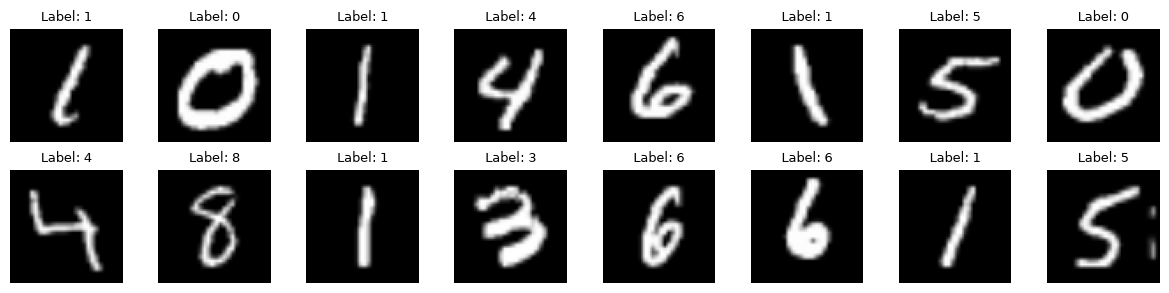

In [5]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

transform = transforms.Compose([
    transforms.Resize((64,64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,), std=(0.5,))  
])

train_dataset = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
test_dataset  = datasets.MNIST(root='./data', train=False, transform=transform, download=True)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}")
print(f"Batches per epoch: {len(train_loader)}")

images, labels = next(iter(train_loader))

print(f"Batch image tensor shape: {images.shape}")  

fig, axes = plt.subplots(nrows=2, ncols=8, figsize=(12, 3))
for idx, ax in enumerate(axes.flat):
    ax.imshow(images[idx].squeeze(), cmap='gray')
    ax.set_title(f"Label: {labels[idx].item()}", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.show()


In [6]:
torch.min(images)

tensor(-1.)

In [7]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# device = 'cpu'

In [8]:
import torch.nn as nn

# DCGAN

In [ ]:
class Generator(nn.Module):
    def __init__(self , dim = 100):
        super().__init__()
 
        self.net = nn.Sequential(

            nn.ConvTranspose2d(in_channels= 100 ,
                         out_channels = 512 , 
                         kernel_size= 4, 
                         stride =  1 ,
                         padding = 0,
                         bias = False), 

            nn.BatchNorm2d(512),
            nn.ReLU(),


            nn.ConvTranspose2d(in_channels= 512 ,
                         out_channels = 256 , 
                         kernel_size=4 , 
                         stride =  2 ,
                         padding = 1,
                         bias = False), 

            nn.BatchNorm2d(256),
            nn.ReLU(),



            nn.ConvTranspose2d(in_channels= 256 ,
                         out_channels = 128 , 
                         kernel_size=4 , 
                         stride =  2 ,
                         padding = 1,
                         bias = False), 

            nn.BatchNorm2d(128),
            nn.ReLU(),


            nn.ConvTranspose2d(in_channels= 128 ,
                         out_channels = 32 , 
                         kernel_size=4 , 
                         stride =  2 ,
                         padding = 1,
                         bias = False), 

            nn.BatchNorm2d(32),
            nn.ReLU(),


            nn.ConvTranspose2d(in_channels= 32 ,
                         out_channels = 1 , 
                         kernel_size= 4 , 
                         stride =  2 ,
                         padding = 1),
            nn.Tanh()

        )

    def forward(self, x):
        return self.net(x)

    
G = Generator()
G.to(device)

Generator(
  (net): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU()
    (9): ConvTranspose2d(128, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU()
    (12): ConvTranspose2d(32, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (13): Tanh()
  )
)

In [26]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
 
        self.net = nn.Sequential(

            nn.Conv2d(in_channels= 1 ,
                         out_channels = 32 , 
                         kernel_size= 4, 
                         stride =  1 ,
                         padding = 0,
                         bias = False), 

            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2),


            nn.Conv2d(in_channels= 32 ,
                         out_channels = 64 , 
                         kernel_size=4 , 
                         stride =  2 ,
                         padding = 1,
                         bias = False), 

            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),



            nn.Conv2d(in_channels= 64 ,
                         out_channels = 128 , 
                         kernel_size=4 , 
                         stride =  2 , 
                         padding = 1,
                         bias = False), 

            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),


            nn.Conv2d(in_channels= 128 ,
                         out_channels = 256 , 
                         kernel_size=4 , 
                         stride =  2 ,
                         padding = 1,
                         bias = False), 

            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2),


            nn.Conv2d(in_channels= 256 ,
                         out_channels = 512 , 
                         kernel_size= 4 , 
                         stride =  2 ,
                         padding = 1)

        )

    def forward(self, x):
        return self.net(x)

    
D = Discriminator()
D.to(device)

Discriminator(
  (net): Sequential(
    (0): Conv2d(1, 32, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): LeakyReLU(negative_slope=0.2)
    (9): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): LeakyReLU(negative_slope=0.2)
    (12): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  )
)

In [12]:
next(D.parameters()).device

device(type='cuda', index=0)

In [28]:

with torch.no_grad():
    def weights_init(module: nn.Module) -> None:
        if isinstance(module , (nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.normal_(module.weight , mean= 0 , std = 0.02)

            if module.bias is not None:
                nn.init.constant_(module.bias, 0 )


        elif isinstance(module , (nn.BatchNorm2d)):
            nn.init.normal_(module.weight , mean= 0 , std = 0.02)

            if module.bias is not None:
                nn.init.constant_(module.bias, 0 )

In [29]:
G.apply(weights_init)
D.apply(weights_init)

Discriminator(
  (net): Sequential(
    (0): Conv2d(1, 32, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): LeakyReLU(negative_slope=0.2)
    (9): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): LeakyReLU(negative_slope=0.2)
    (12): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  )
)

In [30]:
optimizerG = torch.optim.Adam(params = G.parameters(),
                            lr= 0.0002 ,
                            betas=(0.5, 0.999))

optimizerD = torch.optim.Adam(params = D.parameters(),
                            lr= 0.0002 ,
                            betas=(0.5, 0.999))

In [31]:
loss_fn = nn.BCEWithLogitsLoss()

In [32]:
torch.full_like(torch.ones((2,2)) , 0.2)

tensor([[0.2000, 0.2000],
        [0.2000, 0.2000]])

In [33]:
device

'cuda'

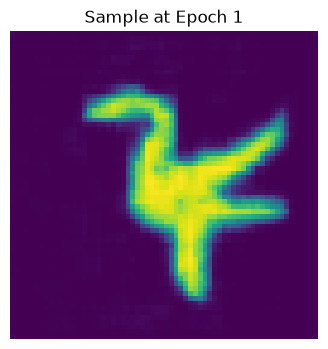

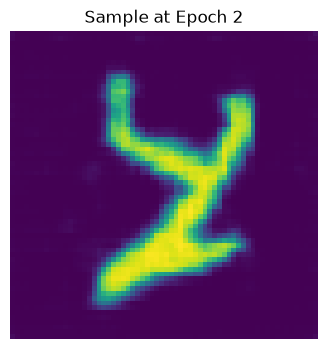

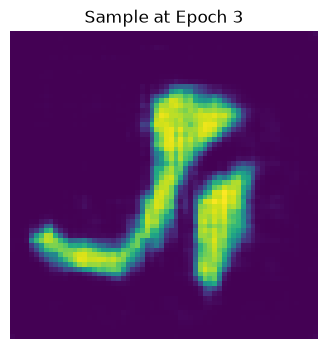

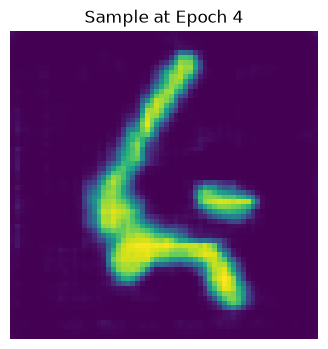

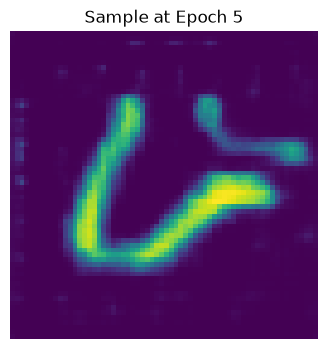

In [36]:
import matplotlib.pyplot as plt

fixed_noise = torch.randn(1, 100, 1, 1, device=device)

EPOCHS = 5

for epoch in range(EPOCHS):
    for real_images, _ in train_loader:
        real_images = real_images.to(device)
        b_size = real_images.size(0)

        optimizerD.zero_grad()

        pred_real = D(real_images)
        loss_real = loss_fn(pred_real, torch.full_like(pred_real, 0.9))

        z = torch.randn(b_size, 100, 1, 1, device=device)
        fake_images = G(z)
        pred_fake = D(fake_images.detach())
        loss_fake = loss_fn(pred_fake, torch.zeros_like(pred_fake))

        lossD = loss_real + loss_fake
        lossD.backward()
        optimizerD.step()

        optimizerG.zero_grad()
        pred_G = D(fake_images)
        lossG = loss_fn(pred_G, torch.ones_like(pred_G))
        lossG.backward()
        optimizerG.step()

    G.eval()
    with torch.no_grad():
        fake_sample = G(fixed_noise).detach().cpu().squeeze(0)
        fake_sample = (fake_sample + 1) / 2.0
        fake_sample = fake_sample.clamp(0, 1)

        img_to_show = fake_sample.permute(1, 2, 0).numpy()

        plt.figure(figsize=(4, 4))
        plt.axis("off")
        plt.title(f"Sample at Epoch {epoch + 1}")
        plt.imshow(img_to_show)
        plt.show()

    G.train()


# WGAN-GP

In [15]:
class Generator(nn.Module):
    def __init__(self , dim = 100):
        super().__init__()
 
        self.net = nn.Sequential(

            nn.ConvTranspose2d(in_channels= 100 ,
                         out_channels = 512 , 
                         kernel_size= 4, 
                         stride =  1 ,
                         padding = 0,
                         bias = False), 

            nn.BatchNorm2d(512),
            nn.ReLU(),


            nn.ConvTranspose2d(in_channels= 512 ,
                         out_channels = 256 , 
                         kernel_size=4 , 
                         stride =  2 ,
                         padding = 1,
                         bias = False), 

            nn.BatchNorm2d(256),
            nn.ReLU(),



            nn.ConvTranspose2d(in_channels= 256 ,
                         out_channels = 128 , 
                         kernel_size=4 , 
                         stride =  2 ,
                         padding = 1,
                         bias = False), 

            nn.BatchNorm2d(128),
            nn.ReLU(),


            nn.ConvTranspose2d(in_channels= 128 ,
                         out_channels = 32 , 
                         kernel_size=4 , 
                         stride =  2 ,
                         padding = 1,
                         bias = False), 

            nn.BatchNorm2d(32),
            nn.ReLU(),


            nn.ConvTranspose2d(in_channels= 32 ,
                         out_channels = 1 , 
                         kernel_size= 4 , 
                         stride =  2 ,
                         padding = 1),
            nn.Tanh()

        )

    def forward(self, x):
        return self.net(x)

    
G = Generator()
G.to(device)

Generator(
  (net): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU()
    (9): ConvTranspose2d(128, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU()
    (12): ConvTranspose2d(32, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (13): Tanh()
  )
)

In [47]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
 
        self.net = nn.Sequential(

            nn.Conv2d(in_channels= 1 ,
                         out_channels = 32 , 
                         kernel_size= 4, 
                         stride =  1 ,
                         padding = 0,
                         bias = False), 

            nn.InstanceNorm2d(32),
            nn.LeakyReLU(0.2),


            nn.Conv2d(in_channels= 32 ,
                         out_channels = 64 , 
                         kernel_size=4 , 
                         stride =  2 ,
                         padding = 1,
                         bias = False), 

            nn.InstanceNorm2d(64),
            nn.LeakyReLU(0.2),



            nn.Conv2d(in_channels= 64 ,
                         out_channels = 128 , 
                         kernel_size=4 , 
                         stride =  2 , 
                         padding = 1,
                         bias = False), 

            nn.InstanceNorm2d(128),
            nn.LeakyReLU(0.2),


            nn.Conv2d(in_channels= 128 ,
                         out_channels = 256 , 
                         kernel_size=4 , 
                         stride =  2 ,
                         padding = 1,
                         bias = False), 

            nn.InstanceNorm2d(256),
            nn.LeakyReLU(0.2),


            nn.Conv2d(in_channels= 256 ,
                         out_channels = 512 , 
                         kernel_size= 4 , 
                         stride =  2 ,
                         padding = 1),

            nn.Conv2d(in_channels= 512 ,
                         out_channels = 1 , 
                         kernel_size= 4 , 
                         stride =  2 ,
                         padding = 1)
        )

    def forward(self, x):
        return self.net(x)

    
D = Discriminator()
D.to(device)

Discriminator(
  (net): Sequential(
    (0): Conv2d(1, 32, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): InstanceNorm2d(32, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): InstanceNorm2d(64, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): InstanceNorm2d(128, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (8): LeakyReLU(negative_slope=0.2)
    (9): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): InstanceNorm2d(256, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (11): LeakyReLU(negative_slope=0.2)
    (12): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (13): Conv2d

In [48]:
optimizerG = torch.optim.Adam(params = G.parameters(),
                            lr= 0.0002 ,
                            betas=(0.0, 0.9))

optimizerD = torch.optim.Adam(params = D.parameters(),
                            lr= 0.0002 ,
                            betas=(0.0, 0.9))

In [49]:
def loss_GP(batch_size , x_real , x_fake , D):
    eps = torch.rand(batch_size , 1 , 1 , 1 , device = device)

    x_hat = (eps * x_real + (1-eps) * x_fake).requires_grad_(True)
    x_hat.requires_grad_(True)

    grad = torch.autograd.grad( D(x_hat) ,
                                x_hat , 
                                grad_outputs= torch.ones_like(D(x_hat)) , 
                                create_graph = True,
                                retain_graph=True,
                                only_inputs=True )[0]

    grad_flaten = grad.reshape(batch_size , -1)

    norm_grad = torch.sqrt(torch.sum(grad_flaten ** 2 , dim = 1)+ 1e-12)

    GP = torch.mean((norm_grad - 1) ** 2)

    return GP
    

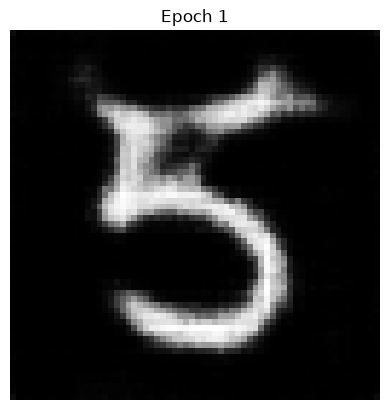

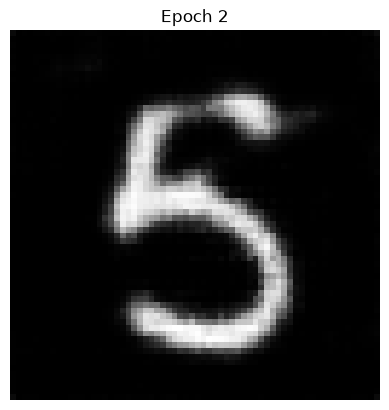

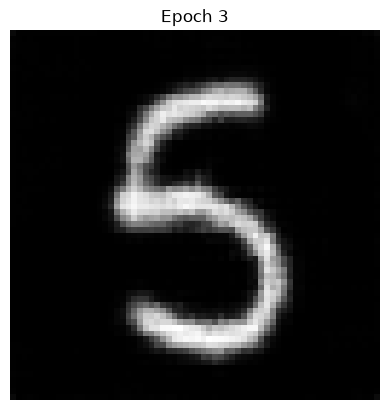

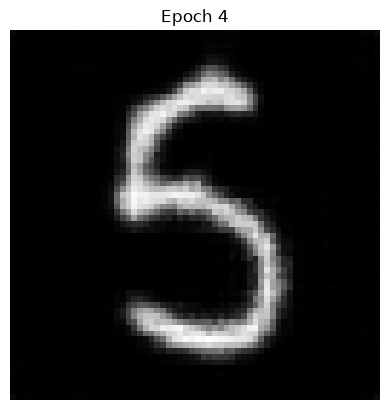

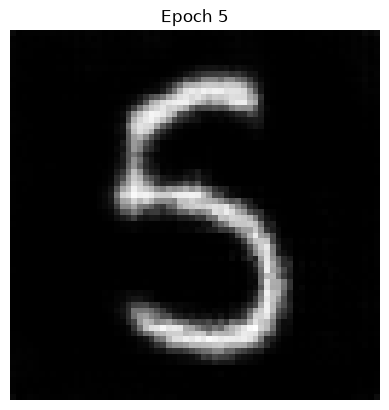

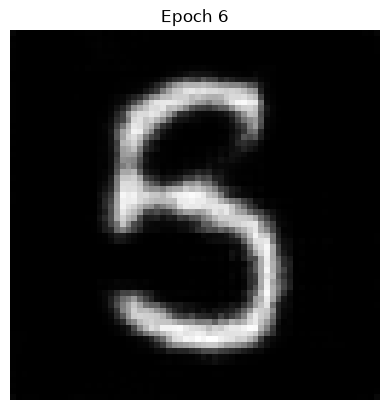

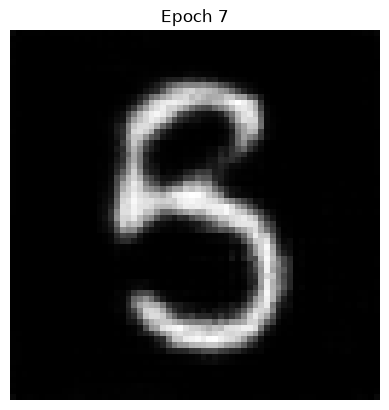

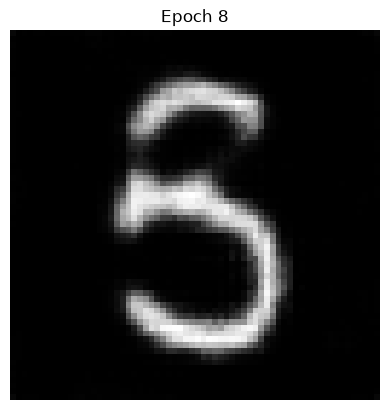

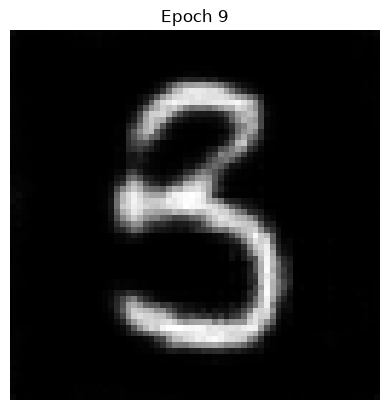

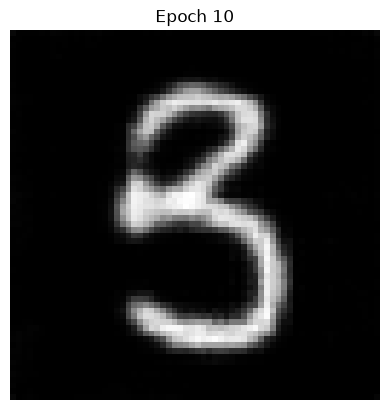

In [50]:
import matplotlib.pyplot as plt

n_critic = 5
lamda = 10 
fixed_noise = torch.randn(1, 100, 1, 1, device=device)

for epoch in range(10):
    for i, (images, _) in enumerate(train_loader):
        batch_size = images.shape[0]
        images = images.to(device)

        optimizerD.zero_grad()

        pred_real = D(images)

        z = torch.randn(batch_size, 100, 1, 1, device=device)
        img_fake = G(z)

        pred_fake = D(img_fake.detach())

        lossD = torch.mean(pred_fake) - torch.mean(pred_real) + lamda * loss_GP(batch_size, images, img_fake.detach(), D)

        lossD.backward()
        optimizerD.step()

        if (i + 1) % n_critic == 0:
            optimizerG.zero_grad()

            fake_img = G(z)
            lossG = -torch.mean(D(fake_img))

            lossG.backward()
            optimizerG.step()

    G.eval()
    with torch.no_grad():
        sample = G(fixed_noise)
        sample = (sample.squeeze().cpu() + 1) / 2.0
        plt.imshow(sample, cmap='gray')
        plt.title(f"Epoch {epoch + 1}")
        plt.axis('off')
        plt.show()
    G.train()


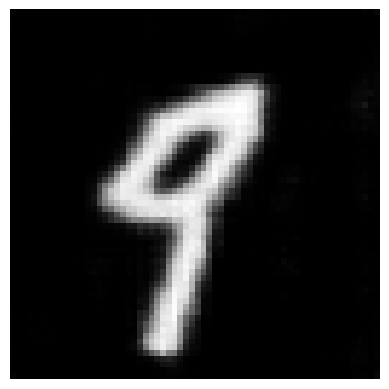

In [69]:
z = torch.randn(1 , 100 , 1 , 1 , device = device).clamp(-1,1)
sample = G(z)
sample = (sample.squeeze().cpu() + 1) / 2.0
plt.imshow(sample.detach(), cmap='gray')
plt.axis('off')
plt.show()